# 04 — Supervisado vs. PatchCore en FabriD v3

Notebook independiente para importar en Kaggle. Compara **YOLO11n-seg** (supervisado) y **PatchCore** (entrenado sólo en normales) sobre el mismo conjunto y máscaras binarias.

**Estado inicial: `MODO_PRUEBA=True`, `EVALUAR_TEST=False`.** Este archivo se entrega sin ejecutar. La prueba usa pocos ejemplos y una época; sus números no son resultados del experimento.

### Antes de ejecutarlo en Kaggle

1. Agregar con **Add Input** el **export anotado de FabriD v3**, con carpetas `train/valid/test`, cada una con `images/labels`. Puede venir dentro de otras carpetas; se detecta automáticamente. Son polígonos YOLO-seg de cuatro clases. **El dataset RAW-FABRID que usaste en 03 no sirve como Input para este notebook.**
2. Activar **GPU T4** e **Internet**. El notebook no descarga FabriD.
3. Importar este notebook. La primera ejecución puede descargar pesos YOLO/ResNet y clona un commit fijo del repositorio.
4. Usar **Save Version → Save & Run All** para conservar notebook y outputs. La prueba no permite sacar conclusiones.
5. Más adelante, para validación completa, cambiar únicamente `MODO_PRUEBA=False`, revisar el presupuesto y guardar otra versión.

El test está reservado: no existe ninguna celda que ejecute inferencia en test. No hay que esperar los tests de 02/03; FabriD requiere su propia validación.

In [1]:
# Parámetros: revisar antes de iniciar Run All
MODO_PRUEBA = False
EVALUAR_TEST = False
SEMILLA = 0

# Opcional: ruta exacta a la carpeta que contiene train, valid y test.
# Vacío = detección automática dentro de /kaggle/input.
RUTA_EXPORT = ""

# Configuraciones INICIALES; no son las ganadoras del experimento FabriD.
EPOCAS_SUPERVISADO = 100
PACIENCIA = 30
IMGSZ_SUPERVISADO = 640
BATCH = 8
BACKBONE_PC = "resnet18"
IMGSZ_PC = 256
CORESET_PC = 0.01

assert EVALUAR_TEST is False, "Este notebook sólo admite preparación y validación."


## 1. Entorno y código

Se reutiliza PatchCore del bloque B, fijando el commit de sus funciones y del manifiesto. Las utilidades específicas de esta comparación se incluyen en el propio notebook para que pueda importarse aunque todavía no estén publicadas en GitHub.

No se instalan ni descargan pesos hasta que vos ejecutes las celdas. Se registran versiones de paquetes y parámetros en el Output.

In [2]:
import sys
import subprocess
import os
import json
import hashlib
import importlib.metadata as metadata
from pathlib import Path

WORK = Path("/kaggle/working")
if not WORK.is_dir():
    raise RuntimeError("Este notebook está preparado para Kaggle.")
REPO = WORK / "tp_final_vision_04"
COMMIT = "3bda925932d0d42cedb49857993e8f1ba28df75d"
if not REPO.exists():
    subprocess.run(["git", "clone", "-q",
                    "https://github.com/victoriapersico/tp_final_vision.git", str(REPO)], check=True)
# Sólo checkout en este clon exclusivo; no se toca ningún notebook 02/03.
subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", COMMIT], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "ultralytics==8.4.215", "sahi==0.14.0", "pycocotools==2.0.11",
                "scipy", "scikit-learn", "pandas", "matplotlib"], check=True)
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

SUFIJO = "_prueba" if MODO_PRUEBA else ""
OUT = WORK / "results" / "fabrid" / ("comparacion04" + SUFIJO)
OUT.mkdir(parents=True, exist_ok=True)
PAQUETES = {p: metadata.version(p) for p in
            ("ultralytics", "sahi", "torch", "torchvision", "numpy", "scipy", "scikit-learn", "Pillow")}
print("Versiones:", PAQUETES)
print("GPU disponible:", torch.cuda.is_available())
print("Output:", OUT)


HEAD is now at 3bda925 Add extended-budget A3 validation notebook


Versiones: {'ultralytics': '8.4.215', 'sahi': '0.14.0', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'numpy': '2.1.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'Pillow': '13.0.0'}
GPU disponible: True
Output: /kaggle/working/results/fabrid/comparacion04


## 2. Funciones de preparación y evaluación

Esta celda incorpora el módulo `fabrid_comparison.py` distribuido con este notebook. No entrena ningún modelo. Las celdas siguientes llaman a estas funciones.

In [3]:
import types
# Copia incluida del módulo para que el notebook sea importable por sí solo.
MODULO_COMPARACION = "\"\"\"Preparación y evaluación común de FabriD v3 (notebook 04).\n\nLa comparación usa el export anotado, no polígonos sobre originales de otra geometría.\nLas cuatro clases se unen en una máscara binaria. Test exige confirmación explícita.\n\"\"\"\nfrom pathlib import Path\nimport csv\nimport json\nimport shutil\n\nimport numpy as np\nfrom PIL import Image, ImageDraw\n\n\ndef load_items(data_root, manifest):\n    \"\"\"Conserva el split auditado y excluye las 19 anotaciones ambiguas.\"\"\"\n    export = Path(data_root) / \"fabrid_v3\" / \"annotations_export\"\n    with Path(manifest).open(newline=\"\") as f:\n        rows = list(csv.DictReader(f))\n    items, assigned = [], {}\n    for row in rows:\n        if row[\"usar_comparacion_comun\"].lower() != \"true\":\n            continue\n        split, group = row[\"split_propuesto\"], row[\"source_id\"]\n        if split not in (\"train\", \"valid\", \"test\"):\n            raise ValueError(f\"Split desconocido: {split}\")\n        if group in assigned and assigned[group] != split:\n            raise ValueError(f\"Fuga entre splits: {group}\")\n        assigned[group] = split\n        path = export / row[\"ruta_relativa\"]\n        label_path = path.parent.parent / \"labels\" / (path.stem + \".txt\")\n        if not path.is_file() or not label_path.is_file():\n            raise FileNotFoundError(f\"Falta imagen o etiqueta de {path}\")\n        items.append({\"id\": row[\"archivo\"], \"source_id\": group, \"split\": split,\n                      \"label\": int(row[\"estado_binario\"] != \"normal\"),\n                      \"path\": path, \"label_path\": label_path})\n    if len({i[\"id\"] for i in items}) != len(items):\n        raise ValueError(\"Identificadores duplicados\")\n    return items\n\n\ndef binary_mask(item):\n    \"\"\"Rasteriza la unión de polígonos a la resolución real del export.\"\"\"\n    with Image.open(item[\"path\"]) as im:\n        w, h = im.size\n    mask = Image.new(\"L\", (w, h), 0)\n    draw = ImageDraw.Draw(mask)\n    for line in item[\"label_path\"].read_text().splitlines():\n        if not line.strip():\n            continue\n        values = list(map(float, line.split()))\n        coords = values[1:]\n        if len(coords) < 6 or len(coords) % 2 or not all(0 <= v <= 1 for v in coords):\n            raise ValueError(f\"Polígono inválido: {item['label_path']}\")\n        points = [(min(w-1, x*w), min(h-1, y*h)) for x, y in zip(coords[::2], coords[1::2])]\n        draw.polygon(points, fill=1)\n    result = np.asarray(mask, dtype=bool)\n    if bool(result.any()) != bool(item[\"label\"]):\n        raise ValueError(f\"Etiqueta binaria y máscara no coinciden: {item['id']}\")\n    return result\n\n\ndef prepare_yolo(items, destination):\n    \"\"\"Dataset YOLO-seg derivado; sólo train/valid, sin escribir originales.\"\"\"\n    destination = Path(destination).resolve()\n    lists = {\"train\": [], \"valid\": []}\n    for item in items:\n        if item[\"split\"] == \"test\":\n            continue\n        lists[item[\"split\"]].append(str(destination / item[\"split\"] / \"images\" / item[\"path\"].name))\n        for kind, source in ((\"images\", item[\"path\"]), (\"labels\", item[\"label_path\"])):\n            target = destination / item[\"split\"] / kind / source.name\n            target.parent.mkdir(parents=True, exist_ok=True)\n            if not target.exists():\n                if kind == \"images\":\n                    target.symlink_to(source.resolve())\n                else:\n                    shutil.copy2(source, target)\n    for split, paths in lists.items():\n        if not paths:\n            raise ValueError(f\"No hay imágenes en {split}\")\n        (destination / f\"{split}.txt\").write_text(\"\\n\".join(paths) + \"\\n\")\n    yaml = destination / \"data.yaml\"\n    yaml.write_text(f\"path: {json.dumps(str(destination))}\\ntrain: train.txt\\nval: valid.txt\\n\"\n                    \"names:\\n  0: Needle Mark Defect\\n  1: hole Defect\\n\"\n                    \"  2: missing yarn Defect\\n  3: stain Defect\\n\")\n    return yaml\n\n\ndef predict_yolo(model, items, imgsz=640):\n    \"\"\"Unión de máscaras de instancia ponderadas por confianza; fondo = 0.\n\n    Este puntaje no es una probabilidad semántica calibrada. El corte de confianza\n    0.001 y NMS del predictor limitan la curva ROC; se documentan como limitación.\n    \"\"\"\n    maps = []\n    for item in items:\n        result = model.predict(str(item[\"path\"]), imgsz=imgsz, conf=0.001,\n                               retina_masks=True, verbose=False)[0]\n        score = np.zeros(result.orig_shape, np.float32)\n        if result.masks is not None:\n            masks = result.masks.data.cpu().numpy()\n            confidences = result.boxes.conf.cpu().numpy()\n            for mask, conf in zip(masks, confidences):\n                if mask.shape != score.shape:\n                    raise ValueError(\"La máscara de YOLO no está en coordenadas del export\")\n                score = np.maximum(score, mask * conf)\n        maps.append(score)\n    return maps\n\n\ndef fit_patchcore(train_items, **config):\n    \"\"\"Reutiliza PatchCore del bloque B; se ajusta desde cero en normales FabriD.\"\"\"\n    from anomaly_baseline import PatchCore\n    if not train_items or any(i[\"split\"] != \"train\" or i[\"label\"] != 0 for i in train_items):\n        raise ValueError(\"PatchCore sólo admite normales de train\")\n    method = PatchCore(**config)\n    method.fit(train_items)\n    return method\n\n\ndef predict_patchcore(method, items):\n    from anomaly_baseline import load_image\n    maps = []\n    for item in items:\n        raw = method.predict_batch(load_image(item[\"path\"], method.size)[None])[0]\n        with Image.open(item[\"path\"]) as im:\n            maps.append(np.asarray(Image.fromarray(raw.astype(np.float32)).resize(\n                im.size, Image.Resampling.BILINEAR)))\n    return maps\n\n\ndef validate_maps(items, maps):\n    if len(items) != len(maps) or not items:\n        raise ValueError(\"Debe haber exactamente un mapa por imagen, en el mismo orden\")\n    for item, score in zip(items, maps):\n        with Image.open(item[\"path\"]) as im:\n            expected = (im.height, im.width)\n        if np.shape(score) != expected or not np.isfinite(score).all():\n            raise ValueError(f\"Mapa inválido: {item['id']}\")\n\n\ndef choose_threshold(items, maps, bins=512):\n    \"\"\"Elige un umbral global por método maximizando Dice micro en valid.\n\n    Se recorre una grilla global, sin normalizar cada imagen por separado.\n    En empate se elige el umbral mayor (menos falsos positivos).\n    \"\"\"\n    if any(i[\"split\"] != \"valid\" for i in items):\n        raise ValueError(\"El umbral sólo se puede elegir con validación\")\n    validate_maps(items, maps)\n    lo, hi = min(float(m.min()) for m in maps), max(float(m.max()) for m in maps)\n    edges = np.linspace(lo, np.nextafter(hi, np.inf), bins + 1)\n    if lo == hi:\n        edges = np.linspace(lo, hi + 1e-6, bins + 1)\n    pos, neg = np.zeros(bins), np.zeros(bins)\n    for item, m in zip(items, maps):\n        mask = binary_mask(item)\n        pos += np.histogram(m[mask], edges)[0]\n        neg += np.histogram(m[~mask], edges)[0]\n    tp, fp = np.cumsum(pos[::-1])[::-1], np.cumsum(neg[::-1])[::-1]\n    dice = 2 * tp / np.maximum(tp + fp + pos.sum(), 1)\n    # El último candidato no predice ningún píxel.\n    values = np.r_[dice, 0.0]\n    return float(edges[np.flatnonzero(values == values.max())[-1]])\n\n\ndef evaluate_maps(items, maps, threshold, bins=2048, confirm_test=False):\n    \"\"\"AUROC imagen exacto, AUROC píxel/AUPRO histogramados y Dice/IoU micro.\n\n    Máscaras en resolución del export. PRO: regiones conexas con conectividad 4;\n    FPR calculado sobre todo el fondo, incluidas imágenes sanas. AUPRO normalizado\n    hasta FPR 0.3. Dice/IoU se agregan por píxel, sin premiar normales vacías\n    con Dice=1 por imagen. No se producen intervalos tratando derivados como independientes.\n    \"\"\"\n    from scipy.ndimage import label\n    from sklearn.metrics import roc_auc_score\n    if len({i[\"split\"] for i in items}) != 1:\n        raise ValueError(\"Evaluar un split por vez\")\n    if any(i[\"split\"] == \"test\" for i in items) and not confirm_test:\n        raise ValueError(\"Test cerrado: requiere confirm_test=True y umbral congelado de valid\")\n    validate_maps(items, maps)\n    lo, hi = min(float(m.min()) for m in maps), max(float(m.max()) for m in maps)\n    edges = np.linspace(lo, hi + max(1e-6, abs(hi)*1e-6), bins + 1)\n    pos, neg, regions = np.zeros(bins), np.zeros(bins), []\n    tp = fp = fn = 0\n    for item, m in zip(items, maps):\n        mask = binary_mask(item)\n        pred = m >= threshold\n        tp += int((pred & mask).sum())\n        fp += int((pred & ~mask).sum())\n        fn += int((~pred & mask).sum())\n        pos += np.histogram(m[mask], edges)[0]\n        neg += np.histogram(m[~mask], edges)[0]\n        components, n = label(mask)\n        for k in range(1, n+1):\n            hist = np.histogram(m[components == k], edges)[0]\n            regions.append(hist / hist.sum())\n    if not pos.sum() or not neg.sum():\n        raise ValueError(\"AUROC píxel/AUPRO requieren píxeles sanos y defectuosos\")\n    fpr = np.r_[0, np.cumsum(neg[::-1]) / neg.sum()]\n    tpr = np.r_[0, np.cumsum(pos[::-1]) / pos.sum()]\n    pro = np.r_[0, np.cumsum(np.mean(regions, axis=0)[::-1])]\n    # Recorta el último segmento en FPR=0.3 e integra incluyendo tramos verticales.\n    aupro = 0.0\n    for x0, x1, y0, y1 in zip(fpr[:-1], fpr[1:], pro[:-1], pro[1:]):\n        if x0 >= 0.3:\n            break\n        if x1 > x0:\n            end = min(x1, 0.3)\n            yend = y0 + (y1-y0) * (end-x0) / (x1-x0)\n            aupro += (end-x0) * (y0+yend) / 2\n    integrate = np.trapezoid if hasattr(np, \"trapezoid\") else np.trapz\n    labels = [i[\"label\"] for i in items]\n    image_auc = float(roc_auc_score(labels, [m.max() for m in maps])) if len(set(labels)) == 2 else None\n    return {\"AUROC_imagen\": image_auc, \"AUROC_pixel\": float(integrate(tpr, fpr)),\n            \"AUPRO@0.3\": float(aupro / 0.3), \"Dice_micro\": 2*tp / max(2*tp+fp+fn, 1),\n            \"IoU_micro\": tp / max(tp+fp+fn, 1), \"umbral_valid\": float(threshold),\n            \"imagenes\": len(items), \"fuentes\": len({i['source_id'] for i in items}),\n            \"bins\": bins, \"split\": items[0][\"split\"]}\n"
fc = types.ModuleType("fabrid_comparison")
exec(compile(MODULO_COMPARACION, "fabrid_comparison.py", "exec"), fc.__dict__)
(OUT / "fabrid_comparison.py").write_text(MODULO_COMPARACION)


10059

## 3. FabriD y split común

Se conserva `reports/fabrid/fab4_split_agrupado.csv`, agrupado por `source_id`. Se excluyen los 19 ambiguos.

| Split completo | Normales | Defectuosas |
|---|---:|---:|
| Train | 429 | 1221 |
| Valid | 93 | 282 |
| Test reservado | 85 | 278 |

Leer el manifiesto permite auditar que no hay fuentes cruzadas; no se calculan predicciones de test. PatchCore se ajusta exclusivamente con normales de **train**. El segmentador usa normales con etiquetas vacías y defectuosas con polígonos.

In [4]:
def es_export(path):
    return all((path / s / k).is_dir()
               for s in ("train", "valid", "test") for k in ("images", "labels"))

if RUTA_EXPORT:
    export = Path(RUTA_EXPORT)
    if not es_export(export):
        raise FileNotFoundError("RUTA_EXPORT debe contener train/valid/test con images/labels.")
else:
    candidatos = sorted({p.parent for p in Path("/kaggle/input").rglob("train")
                         if p.is_dir() and es_export(p.parent)})
    if len(candidatos) != 1:
        raise RuntimeError("Agregá el export FabriD v3 en Add Input o indicá RUTA_EXPORT. "
                           + "Carpetas detectadas: " + str(candidatos))
    export = candidatos[0]

# Las imágenes quedan en el Input (sólo lectura); derivados fuera del Output.
DATA = Path("/tmp/rewear_fabrid04")
destino = DATA / "fabrid_v3" / "annotations_export"
destino.parent.mkdir(parents=True, exist_ok=True)
if destino.is_symlink() and destino.resolve() != export.resolve():
    raise RuntimeError("El Input cambió en esta sesión. Reiniciar la sesión para cambiar de dataset.")
if not destino.exists():
    destino.symlink_to(export.resolve(), target_is_directory=True)
os.environ["REWEAR_DATA_DIR"] = str(DATA)

manifest = REPO / "reports/fabrid/fab4_split_agrupado.csv"
items = fc.load_items(DATA, manifest)
splits = {s: [i for i in items if i["split"] == s] for s in ("train", "valid", "test")}
conteos = pd.DataFrame({s: {"normales": sum(i["label"] == 0 for i in rows),
                           "defectuosas": sum(i["label"] == 1 for i in rows)}
                       for s, rows in splits.items()}).T
assert conteos.values.tolist() == [[429, 1221], [93, 282], [85, 278]], "Revisar versión del dataset."
display(conteos)

def subconjunto(rows, n_por_clase):
    rng = np.random.default_rng(SEMILLA)
    elegidos = []
    for valor in (0, 1):
        candidatos = sorted([i for i in rows if i["label"] == valor], key=lambda i: i["id"])
        if not candidatos:
            raise ValueError("El split no tiene ambas clases.")
        indices = rng.choice(len(candidatos), min(n_por_clase, len(candidatos)), replace=False)
        elegidos.extend(candidatos[int(j)] for j in indices)
    return elegidos

train = subconjunto(splits["train"], 4) if MODO_PRUEBA else splits["train"]
valid = subconjunto(splits["valid"], 2) if MODO_PRUEBA else splits["valid"]
normales_train = [i for i in train if i["label"] == 0]
print("Datos efectivos:", len(train), "train;", len(valid), "valid;",
      len(normales_train), "normales para PatchCore")
pd.DataFrame([{k: str(v) for k, v in i.items()} for i in train + valid]).to_csv(
    OUT / "manifiesto_efectivo.csv", index=False)
CONFIG = dict(modo_prueba=MODO_PRUEBA, evaluar_test=False, semilla=SEMILLA,
              commit=COMMIT, paquetes=PAQUETES,
              manifiesto_sha256=hashlib.sha256(manifest.read_bytes()).hexdigest(),
              export=str(export), pc=dict(backbone=BACKBONE_PC, size=IMGSZ_PC, coreset=CORESET_PC),
              supervisado=dict(imgsz=IMGSZ_SUPERVISADO, batch=BATCH,
                               epochs=1 if MODO_PRUEBA else EPOCAS_SUPERVISADO,
                               patience=1 if MODO_PRUEBA else PACIENCIA))
(OUT / "configuracion.json").write_text(json.dumps(CONFIG, ensure_ascii=False, indent=2))


,normales,defectuosas
train,429,1221
valid,93,282
test,85,278


Datos efectivos: 1650 train; 375 valid; 429 normales para PatchCore


721

## 4. Inspección de máscaras

Los polígonos corresponden a las **imágenes del export**, no a originales de alta resolución. Se rasterizan a su resolución real y se unen las cuatro clases en una máscara binaria. En normales, la máscara debe estar vacía.

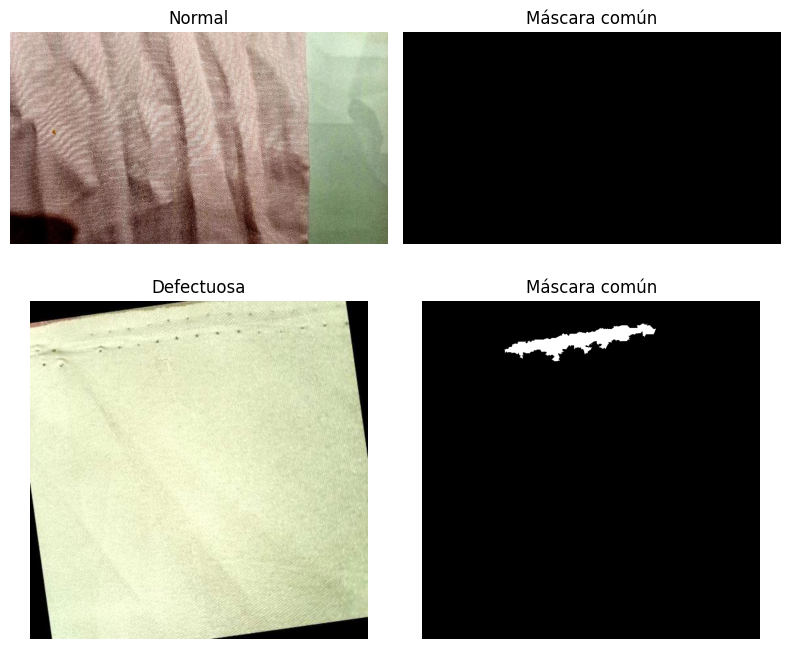

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for row, clase in enumerate((0, 1)):
    item = next(i for i in valid if i["label"] == clase)
    with Image.open(item["path"]) as im:
        axes[row, 0].imshow(im.convert("RGB"))
    axes[row, 0].set_title("Normal" if clase == 0 else "Defectuosa")
    axes[row, 1].imshow(fc.binary_mask(item), cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Máscara común")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "mascaras_valid.png", dpi=130)


## 5. Métricas compatibles fijadas antes de entrenar

| Métrica | Significado | Regla para ambos |
|---|---|---|
| AUROC imagen | Separar imágenes sanas/defectuosas | Máximo del mapa por imagen |
| AUROC píxel | Separar píxeles sanos/defectuosos | Geometría del export, máscara común |
| AUPRO@0.3 | Localización con igual peso por región | Conectividad 4; integrar hasta FPR 0,3 y normalizar |
| Dice/IoU micro | Superposición binaria | Umbral global por método elegido por Dice en valid |

AUPRO@0.3 es la métrica principal propuesta para la localización. AUROC píxel y AUPRO usan 2048 bins globales. Dice/IoU agregan TP/FP/FN sobre todo el split: las imágenes sanas aportan falsos positivos y no un Dice=1 por estar vacías. No se normalizan mapas individualmente.

YOLO produce la unión de máscaras de instancia ponderadas por confianza, fondo cero. No es una probabilidad semántica calibrada; confianza mínima 0,001 y NMS limitan sus curvas. PatchCore produce distancias al banco normal; su mapa se interpola a la geometría del export. Las escalas crudas no se comparan; cada modelo tiene su propio umbral.

Las entradas de los modelos tienen resoluciones diferentes (640 vs. 256): reportar esa decisión y el tiempo junto a las métricas. No es una comparación de arquitecturas con igual supervisión ni presupuesto.

Los intervalos definitivos deberán remuestrear **source_id**, no derivados independientes; no se calculan en esta preparación. La prueba corta no permite seleccionar modelos ni estimar rendimiento real.

## 6. Segmentación supervisada

YOLO11n-seg preentrenado, ajustado en FabriD. En modo prueba: una época y ocho imágenes train. El mejor checkpoint se elige con validación de YOLO; la comparación final usa las máscaras binarias comunes.

Se guarda en un nombre diferente del notebook 02. No se entrena ni se infiere sobre test.

In [6]:
from ultralytics import YOLO

yaml = fc.prepare_yolo(train + valid, DATA / "derived" / ("fabrid04" + SUFIJO))
run = OUT / "yolo11n_seg"
firma = json.dumps(CONFIG["supervisado"], sort_keys=True)
marca = run / "completado.json"
if marca.exists():
    assert marca.read_text() == firma, "Cambió la configuración: crear otra versión/salida."
    sup = YOLO(str(run / "weights/best.pt"))
else:
    sup = YOLO("yolo11n-seg.pt")
    sup.train(data=str(yaml), project=str(OUT), name=run.name, exist_ok=True,
              **CONFIG["supervisado"], seed=SEMILLA, deterministic=True,
              workers=2, device=0 if torch.cuda.is_available() else "cpu")
    sup = YOLO(str(run / "weights/best.pt"))
    marca.write_text(firma)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/tmp/rewear_fabrid04/derived/fabrid04/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynami

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      1.74G      2.578      3.915      3.511      2.103          0          9        640: 100% ━━━━━━━━━━━━ 207/207 8.6it/s 23.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 7.6it/s 3.2s
                   all        375        409      0.154      0.152     0.0801     0.0309       0.16      0.122     0.0782     0.0319

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
      3/100      1.74G      2.559      3.876      3.386      2.122          0          0        640: 100% ━━━━━━━━━━━━ 207/207 8.7it/s 23.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 7.5it/s 3.2s
                   all        375        409      0.144      0.207      0.079     0.0279      0.151      0.197     0.0713     0.0236

      Ep

## 7. PatchCore

Se reutiliza la implementación del bloque B; se ajusta **desde cero con normales FabriD**. Configuración inicial ResNet18, entrada 256 y coreset 1 %. Esta implementación corre en CPU aunque haya GPU disponible; la GPU se usa en YOLO.

Se conserva el banco de memoria. La resolución cuadrada de entrada de PatchCore es una limitación que debe declararse.

In [7]:
import anomaly_baseline as ab

pc = ab.PatchCore(backbone=BACKBONE_PC, size=IMGSZ_PC, coreset=CORESET_PC, seed=SEMILLA)
banco = OUT / "patchcore_memoria.npz"
meta_pc = OUT / "patchcore_completado.json"
firma_pc = json.dumps(dict(CONFIG["pc"], semilla=SEMILLA,
                           train=[i["id"] for i in normales_train]), sort_keys=True)
if banco.exists() and meta_pc.exists():
    assert meta_pc.read_text() == firma_pc, "Cambió PatchCore: crear otra versión/salida."
    with np.load(banco) as saved:
        pc.state = {key: saved[key] for key in saved.files}
else:
    if any(i["split"] != "train" or i["label"] != 0 for i in normales_train):
        raise ValueError("PatchCore sólo puede usar normales de train.")
    pc.fit(normales_train)
    np.savez_compressed(banco, **pc.state)
    meta_pc.write_text(firma_pc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


## 8. Validación común y conservación de resultados

Se evalúan exactamente las mismas imágenes para ambos modelos. El umbral por método maximiza Dice micro en valid (grilla de 512 candidatos); el test continúa cerrado. Se guardan mapas, configuración, métricas y umbrales.

En modo prueba, los resultados se identifican como prueba de funcionamiento, no evidencia experimental.

In [8]:
import time

resultados = {}
for nombre, predecir in (
    ("YOLO11n-seg", lambda: fc.predict_yolo(sup, valid, imgsz=IMGSZ_SUPERVISADO)),
    ("PatchCore", lambda: fc.predict_patchcore(pc, valid)),
):
    inicio = time.perf_counter()
    scores = predecir()
    segundos = (time.perf_counter() - inicio) / len(valid)
    threshold = fc.choose_threshold(valid, scores)
    metricas = fc.evaluate_maps(valid, scores, threshold)
    metricas["segundos_por_imagen"] = segundos
    metricas["modo_prueba"] = MODO_PRUEBA
    resultados[nombre] = metricas
    carpeta = OUT / nombre.replace("-", "_")
    carpeta.mkdir(exist_ok=True)
    np.savez_compressed(carpeta / "mapas_valid.npz",
                        **{f"map_{j:04d}": m for j, m in enumerate(scores)})
    (carpeta / "orden_imagenes.json").write_text(json.dumps([i["id"] for i in valid]))
    (carpeta / "metricas_valid.json").write_text(json.dumps(metricas, indent=2))
    del scores

display(pd.DataFrame(resultados).T)
(OUT / "metricas_valid.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2))
print("PRUEBA DE FUNCIONAMIENTO: no interpretar las métricas." if MODO_PRUEBA
      else "Validación completa. Seleccionar configuración aquí, antes de abrir test.")
print("No se evaluó test.")


/kaggle/working/tp_final_vision_04/src/anomaly_baseline.py:207: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  x = torch.from_numpy(images).permute(0, 3, 1, 2).float() / 255


,AUROC_imagen,AUROC_pixel,AUPRO@0.3,Dice_micro,IoU_micro,umbral_valid,imagenes,fuentes,bins,split,segundos_por_imagen,modo_prueba
YOLO11n-seg,0.939068,0.862916,0.773463,0.522513,0.35365,0.16507,375,363,2048,valid,0.029863,False
PatchCore,0.606955,0.742602,0.412761,0.104201,0.054964,2.669366,375,363,2048,valid,0.062072,False


Validación completa. Seleccionar configuración aquí, antes de abrir test.
No se evaluó test.


## 9. Exportación y próximos pasos

El notebook ejecutado se conserva en la versión de Kaggle. El ZIP contiene la carpeta `results/` con pesos, banco PatchCore, mapas valid, métricas y configuración. Descomprimir en la raíz local del proyecto; `results/` no se versiona en Git.

Después de la prueba: revisar máscaras y predicciones, decidir configuración/presupuesto y realizar validación completa. El entrenamiento completo de PatchCore puede ser costoso en CPU. No lanzar corridas definitivas sin revisar recursos.

Antes del test común deben congelarse configuraciones, umbrales, checkpoints y elección de agregación. Los intervalos agrupados y desgloses por clase/lote son trabajo posterior. Este notebook no genera resultados de test.

**Fuentes:** FabriD v3 (Mendeley, CC BY 4.0), `docs/DATASETS.md`, `reports/fabrid/eda_fabrid.md`; YOLO/Ultralytics y PatchCore (Roth et al., CVPR 2022). Conservar atribuciones. El sesgo de lote/resolución de FabriD limita la generalización a prendas.

In [9]:
import shutil
etiqueta = "results_fabrid04" + SUFIJO
zip_path = shutil.make_archive(str(WORK / etiqueta), "zip", root_dir=WORK, base_dir="results")
print("Archivo para descargar en Output:", zip_path)
print("Usar la versión Successful de Kaggle para descargar el notebook ejecutado.")


Archivo para descargar en Output: /kaggle/working/results_fabrid04.zip
Usar la versión Successful de Kaggle para descargar el notebook ejecutado.
